# Лекція 4. Трансформери та мовні моделі.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [1]:
import importlib.util
import importlib.metadata
import subprocess
import sys

if importlib.util.find_spec('torch') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'torch>=2.6,<3', '--index-url', 'https://download.pytorch.org/whl/cpu'])
packages = {'numpy': 'numpy>=1.26,<3', 'pandas': 'pandas>=2.2,<4',
    'matplotlib': 'matplotlib>=3.8,<4', 'transformers': 'transformers[sentencepiece]==5.18.0',
    'datasets': 'datasets>=3,<6', 'evaluate': 'evaluate>=0.4,<1',
    'gradio': 'gradio>=5,<7', 'tensorboard': 'tensorboard>=2.16,<3',
    'IPython': 'ipython>=8', 'sentencepiece': 'sentencepiece>=0.2',
    'zstandard': 'zstandard>=0.22', 'accelerate': 'accelerate>=1',
    'sacremoses': 'sacremoses>=0.1'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if importlib.util.find_spec('transformers') is not None:
    if importlib.metadata.version('transformers') != '5.18.0':
        missing.append('transformers[sentencepiece]==5.18.0')
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import copy
import gc
import hashlib
import json
import math
import os
import random
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, normalizers
from torch.utils.tensorboard import SummaryWriter
from IPython.display import display, Markdown
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def clear_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def train_bpe(documents, vocab_size):
    tokenizer = Tokenizer(models.BPE(unk_token='<unk>'))
    tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tokenizer.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=['<unk>', '<eos>'], initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False)
    tokenizer.train_from_iterator(documents, trainer=trainer)
    return tokenizer

def encode_documents(documents, tokenizer, batch_size=128):
    chunks = []
    eos_id = tokenizer.token_to_id('<eos>')
    for start in range(0, len(documents), batch_size):
        encoded = tokenizer.encode_batch(documents[start:start + batch_size])
        chunks.extend((np.asarray(item.ids + [eos_id], dtype=np.int32) for item in encoded))
    return torch.from_numpy(np.concatenate(chunks).astype(np.int64))

def tokenizer_statistics(tokenizer, documents):
    counts = []
    unknown = 0
    token_count = 0
    unknown_id = tokenizer.token_to_id('<unk>')
    for start in range(0, len(documents), 128):
        for encoded in tokenizer.encode_batch(documents[start:start + 128]):
            counts.append(len(encoded.ids))
            unknown += sum((token == unknown_id for token in encoded.ids))
            token_count += len(encoded.ids)
    return {'vocab_size': tokenizer.get_vocab_size(), 'documents': len(counts), 'mean_tokens': float(np.mean(counts)), 'unk_fraction': unknown / max(1, token_count)}

def sample_batch(source, context_len, batch_size, generator, device, return_indices=False):
    positions = torch.randint(len(source) - context_len, (batch_size,), generator=generator)
    x = torch.stack([source[position:position + context_len] for position in positions])
    y = torch.stack([source[position + 1:position + context_len + 1] for position in positions])
    if return_indices:
        return (x.to(device), y.to(device), positions)
    return (x.to(device), y.to(device))
MODEL_KEYS = ['vocab_size', 'embed_dim', 'n_heads', 'n_layers', 'context_len', 'dropout']

def model_from_config(config):
    return MiniGPT(**{key: config[key] for key in MODEL_KEYS})

@torch.no_grad()
def estimate_loss(model, splits, config, device):
    was_training = model.training
    model.eval()
    rng = torch.Generator().manual_seed(SEED + 200)
    result = {}
    for name, source in splits.items():
        losses = []
        for _ in range(config['eval_iters']):
            x, y = sample_batch(source, config['context_len'], config['batch_size'], rng, device)
            _, loss = model(x, y)
            losses.append(loss.item())
        result[name] = float(np.mean(losses))
    model.train(was_training)
    return result

def train_minigpt(name, config, splits, tokenizer, artifact_dir, device):
    set_seed()
    model = model_from_config(config).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config['learning_rate'])
    training_rng = torch.Generator().manual_seed(SEED + 100)
    run_path = artifact_dir / 'runs' / name
    run_path.mkdir(parents=True, exist_ok=True)
    model_path = artifact_dir / 'models'
    model_path.mkdir(exist_ok=True)
    writer = SummaryWriter(str(run_path), purge_step=0)
    history = []
    best_val_loss = float('inf')
    best_iteration = 0
    evaluation_seconds = 0.0
    start_time = time.perf_counter()

    def evaluate(iteration):
        nonlocal best_val_loss, best_iteration, evaluation_seconds
        before = time.perf_counter()
        losses = estimate_loss(model, splits, config, device)
        evaluation_seconds += time.perf_counter() - before
        history.append({'iteration': iteration, 'train_loss': losses['train'], 'val_loss': losses['val']})
        writer.add_scalar('Loss/train', losses['train'], iteration)
        writer.add_scalar('Loss/val', losses['val'], iteration)
        checkpoint = {'config': dict(config), 'model_state_dict': {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}, 'tokenizer_json': tokenizer.to_str(), 'iteration': iteration, 'val_loss': losses['val'], 'seed': SEED}
        if iteration == 0:
            torch.save(checkpoint, model_path / f'{name}_first.pt')
        if losses['val'] < best_val_loss:
            best_val_loss, best_iteration = (losses['val'], iteration)
            torch.save(checkpoint, model_path / f'{name}.pt')
        if iteration % max(config['eval_interval'], 100) == 0 or iteration == config['max_iters']:
            print(f"{name}: iter={iteration}, train={losses['train']:.4f}, val={losses['val']:.4f}", flush=True)
    try:
        evaluate(0)
        for iteration in range(1, config['max_iters'] + 1):
            model.train()
            x, y = sample_batch(splits['train'], config['context_len'], config['batch_size'], training_rng, device)
            _, loss = model(x, y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            if iteration % config['eval_interval'] == 0 or iteration == config['max_iters']:
                evaluate(iteration)
    finally:
        writer.close()
    total_seconds = time.perf_counter() - start_time
    history = pd.DataFrame(history)
    history.to_csv(run_path / 'history.csv', index=False)
    record = {'model': name, 'val_loss': best_val_loss, 'best_iteration': best_iteration, 'last_iteration': config['max_iters'], 'parameters': sum((p.numel() for p in model.parameters())), 'training_seconds': total_seconds, 'evaluation_seconds': evaluation_seconds, 'eval_points': len(history), **config}
    (run_path / 'summary.json').write_text(json.dumps(record, indent=2), encoding='utf-8')
    del model, optimizer, loss, x, y
    clear_memory()
    return (record, history)

def generate_checkpoint(path, prompt, max_new_tokens=60, temperature=0.8, top_k=40):
    checkpoint = torch.load(path, map_location='cpu', weights_only=True)
    tokenizer = Tokenizer.from_str(checkpoint['tokenizer_json'])
    model = model_from_config(checkpoint['config'])
    model.load_state_dict(checkpoint['model_state_dict'])
    ids = torch.tensor([tokenizer.encode(prompt).ids], dtype=torch.long)
    set_seed(SEED + 7)
    generated = model.generate(ids, max_new_tokens=max_new_tokens, temperature=temperature, top_k=top_k)
    text = tokenizer.decode(generated[0].tolist())
    del model
    clear_memory()
    return text

def make_pipeline(task, model_id, **kwargs):
    from transformers import pipeline
    return pipeline(task, model=model_id, device=0 if torch.cuda.is_available() else -1, **kwargs)

def show_json(value):

    def convert(item):
        if isinstance(item, np.generic):
            return item.item()
        if isinstance(item, torch.Tensor):
            return item.tolist()
        raise TypeError(type(item).__name__)
    print(json.dumps(value, ensure_ascii=False, indent=2, default=convert))
import tempfile
import urllib.request
torch.set_num_threads(min(4, os.cpu_count() or 1))
set_seed()


### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = 'google.colab' in sys.modules
print('Running in Colab:', IN_COLAB)


Running in Colab: True


### 0.2. Використовуємо графічний прискорювач, якщо доступний.
На Colab зазвичай є безкоштовний GPU (T4).
Використовуємо його, якщо він доступний.
Якщо ні, залишаємося на CPU.

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Використовуємо: cuda
GPU: Tesla T4


### 0.3. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінти mini-GPT й логи TensorBoard пережили
перезапуск.

In [4]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ARTIFACT_DIR = Path('/content/drive/MyDrive/ai_systems/lab3')
else:
    ARTIFACT_DIR = Path.cwd() if Path.cwd().name == 'lab3' else Path.cwd() / 'lab3'
RUNS_DIR = ARTIFACT_DIR / 'runs'
for folder in [ARTIFACT_DIR / 'models', RUNS_DIR, ARTIFACT_DIR / 'tokenizers', ARTIFACT_DIR / 'data']:
    folder.mkdir(parents=True, exist_ok=True)
print('Артефакти зберігаються в:', ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab3


---
## 1. Корпус: українська поезія

Для mini-GPT з нуля потрібен текстовий корпус однією мовою, достатньо
великий, щоб модель могла вивчити бодай прості закономірності.

Використовуємо датасет [`RudyiVT/ukrainian-poems`](https://huggingface.co/datasets/RudyiVT/ukrainian-poems)
(17 918 віршів, 757 авторів, зібрано з [ukrlib.com.ua](https://www.ukrlib.com.ua/))
повністю — весь текст іде в один суцільний корпус для тренування.

### 1.1. Завантажуємо датасет з Hugging Face Hub

In [5]:
from datasets import Dataset
POEMS_URL = 'https://huggingface.co/datasets/RudyiVT/ukrainian-poems/resolve/77c88b284ca375ee469a3ed34011ddf28859d750/data/train-00000-of-00001-3d92810ccd32069e.parquet'
poems_path = Path(tempfile.gettempdir()) / 'lab3_poems.parquet'
if not poems_path.exists():
    urllib.request.urlretrieve(POEMS_URL, poems_path)
poems_dataset = Dataset.from_parquet(str(poems_path))
print('Усього віршів у датасеті:', len(poems_dataset))
print('Колонки:', poems_dataset.column_names)


Generating train split: 0 examples [00:00, ? examples/s]

Усього віршів у датасеті: 17918
Колонки: ['author', 'author_url', 'poem_name', 'poem_url', 'context_author', 'context_poem_name', 'context_poem']


### 1.2. Збираємо суцільний корпус

In [6]:
poems_df = poems_dataset.to_pandas()
poems_list = poems_df['context_poem'].dropna().astype(str).tolist()
corpus_text = '\n\n'.join(poems_list)
print('Розмір корпусу:', len(corpus_text), 'символів')
print('Початок корпусу:', corpus_text[:60])


Розмір корпусу: 60886196 символів
Початок корпусу: У гостинній бавилися розмовою три добре знайомі особи.

Обі 


### 1.3. Базова статистика корпусу

In [7]:
words = corpus_text.split()
unique_words = set(word.lower() for word in words)
print('Слів (з повторами):', len(words))
print('Унікальних слів:', len(unique_words))


Слів (з повторами): 9941806
Унікальних слів: 994965


---
## 2. Токенізація: BPE на власному корпусі

Токенізація перетворює текст на послідовність id. Використовуємо BPE (Byte Pair Encoding),
який досить часто використовується на великих LLM. Тренуємо через `tokenizers` (від HuggingFace)—
переписувати цикл злиття пар вручну немає сенсу: це вже готовий, швидкий (Rust) алгоритм,
а не нова концепція, яку ми тут вивчаємо.

### 2.1. Тренуємо BPE

Тренер бачить датасет як список окремих віршів (а не один суцільний
рядок) — це і природніший спосіб виклику `train_from_iterator`, і легший
для пам'яті: не потрібно тримати весь корпус як один текстовий блок під
час підрахунку частот пар.

In [8]:
VOCAB_SIZE = 16000
SPECIAL_TOKENS = ['<unk>', '<eos>']
bpe_tokenizer = train_bpe(poems_list, VOCAB_SIZE)
bpe_tokenizer.save(str(ARTIFACT_DIR / 'tokenizers/demo_bpe_16000.json'))
bpe_vocab = bpe_tokenizer.get_vocab()
itos = [None] * len(bpe_vocab)
for token, index in bpe_vocab.items():
    itos[index] = token
stoi = bpe_vocab
UNK_ID = stoi['<unk>']
EOS_ID = stoi['<eos>']

def tokenize(text):
    return bpe_tokenizer.encode(text).tokens

def encode(tokens):
    return [stoi.get(token, UNK_ID) for token in tokens]

def decode(ids):
    return bpe_tokenizer.decode(ids)

print('Розмір словника (BPE):', len(itos))


Розмір словника (BPE): 16000


### 2.1.1. Порівняння словників 16000 і 6000

In [9]:
small_bpe = train_bpe(poems_list, 6000)
small_bpe.save(str(ARTIFACT_DIR / 'tokenizers/demo_bpe_6000.json'))
demo_tokenizer_comparison = pd.DataFrame([
    {'tokenizer': 'BPE 16000', **tokenizer_statistics(bpe_tokenizer, poems_list)},
    {'tokenizer': 'BPE 6000', **tokenizer_statistics(small_bpe, poems_list)},
])
display(demo_tokenizer_comparison)
demo_tokenizer_comparison.to_csv(ARTIFACT_DIR / 'data/demo_tokenizer_comparison.csv', index=False)
del small_bpe


,tokenizer,vocab_size,documents,mean_tokens,unk_fraction
0,BPE 16000,16000,17918,1027.798917,0.0
1,BPE 6000,6000,17918,1175.748075,0.0


### 2.2. Кодуємо корпус у послідовність id

Кодуємо пачками (`.encode_batch()`) по кілька сотень віршів, одразу перетворюючи кожен
результат на компактний `numpy` масив (`int32`, 4 байти на токен). Один
виклик `encode()` на весь корпус одразу тримає у пам'яті і список токенів,
і список id для всього тексту разом, що може призвести до вичерпання памʼяті (out of memory, OOM).

In [10]:
ENCODE_BATCH_SIZE = 128
data = encode_documents(poems_list, bpe_tokenizer, ENCODE_BATCH_SIZE)
print('Токенів у корпусі:', len(data))
print('Частка <unk>:', (data == UNK_ID).float().mean().item())
print('Форма:', data.shape, '| dtype:', data.dtype)


Токенів у корпусі: 18434019
Частка <unk>: 0.0
Форма: torch.Size([18434019]) | dtype: torch.int64


### 2.3. Спліт train/val

Для тексту спліт робимо **послідовним** зрізом, а не випадковим
перемішуванням рядків — модель тренується передбачати "наступне слово",
тому послідовність токенів має лишатись цілою.

In [11]:
split_idx = int(len(data) * 0.9)
train_data = data[:split_idx]
val_data = data[split_idx:]

print("train:", train_data.shape, " val:", val_data.shape)


train: torch.Size([16590617])  val: torch.Size([1843402])


---
## 3. Mini-GPT з нуля

Реалізуємо decoder-only трансформер: Query/Key/Value власноруч,
без nn.MultiheadAttention. Мета маленької моделі — дослідити
механіку й криву навчання.

### 3.1. Гіперпараметри

In [12]:
CONTEXT_LEN = 32
EMBED_DIM = 48
N_HEADS = 4
N_LAYERS = 1
DROPOUT = 0.1
BATCH_SIZE = 8
LEARNING_RATE = 0.0005
MAX_ITERS = 400
EVAL_INTERVAL = 50
EVAL_ITERS = 4
assert EMBED_DIM % N_HEADS == 0
HEAD_DIM = EMBED_DIM // N_HEADS
demo_config = {'vocab_size': len(itos), 'embed_dim': EMBED_DIM, 'n_heads': N_HEADS,
    'n_layers': N_LAYERS, 'context_len': CONTEXT_LEN, 'dropout': DROPOUT,
    'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE, 'max_iters': MAX_ITERS,
    'eval_interval': EVAL_INTERVAL, 'eval_iters': EVAL_ITERS}
show_json(demo_config)


{
  "vocab_size": 16000,
  "embed_dim": 48,
  "n_heads": 4,
  "n_layers": 1,
  "context_len": 32,
  "dropout": 0.1,
  "batch_size": 8,
  "learning_rate": 0.0005,
  "max_iters": 400,
  "eval_interval": 50,
  "eval_iters": 4
}


### 3.2. Батчі: випадкові вікна контексту

Кожен приклад — випадковий зріз довжини `CONTEXT_LEN` з корпусу; таргет —
той самий зріз, зсунутий на один токен вперед (передбачаємо наступне слово
для кожної позиції одночасно).

In [13]:
batch_rng = torch.Generator().manual_seed(SEED)

def get_batch(split):
    source = train_data if split == 'train' else val_data
    return sample_batch(source, CONTEXT_LEN, BATCH_SIZE, batch_rng, device)

xb, yb, positions = sample_batch(train_data, CONTEXT_LEN, BATCH_SIZE, batch_rng, device, True)
assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN)
assert torch.equal(xb[:, 1:], yb[:, :-1])
for row, position in enumerate(positions.tolist()):
    assert torch.equal(xb[row].cpu(), train_data[position:position + CONTEXT_LEN])
    assert torch.equal(yb[row].cpu(), train_data[position + 1:position + CONTEXT_LEN + 1])
print('Форма батчу x:', xb.shape, '| y:', yb.shape)
print('Відповідність усіх частин випадкового батчу: OK')


Форма батчу x: torch.Size([8, 32]) | y: torch.Size([8, 32])
Відповідність усіх частин випадкового батчу: OK


### 3.3. Одна attention-голова

Наведемо формулу attention:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

До неї додаємо **причинну маску** (`causal mask`), адже токен на позиції `t` не має права
"дивитися" на токени після себе, інакше модель підглядає відповідь.

In [14]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)


        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v


### 3.4. Multi-head attention

Кілька голів паралельно — кожна вчиться відстежувати інший тип зв'язку між
словами (лекція, розділ "Multi-head attention"). Результати склеюємо
(concat) і пропускаємо ще через один лінійний шар.

In [15]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))


### 3.5. Блок трансформера

Multi-head attention + feed-forward, кожен обгорнутий у residual-зв'язок
і layer normalization — ті самі інструменти стабілізації тренування, що
й у лекції 3, застосовані до нового типу шару.

In [16]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)




class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


### 3.6. Повна модель

Токен-embedding + позиційний embedding (лекція, розділ "Позиційне
кодування") → `N_LAYERS` блоків → фінальний лінійний шар, що повертає
розподіл ймовірностей по всьому словнику для кожної позиції.

In [17]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0,
                 top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


### 3.7. Ініціалізація моделі

In [18]:
model = MiniGPT(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Кількість параметрів: {n_params:,}")


Кількість параметрів: 1,581,760


### 3.8. Тренування

Той самий цикл, що й у попередніх лекціях: forward → loss → backward →
update, лише loss тепер — cross-entropy передбачення наступного токена.
Оцінюємо val loss періодично (`EVAL_INTERVAL`), а не щоразу — оцінка на
`EVAL_ITERS` батчах дешевша й достатньо точна.

In [19]:
demo_splits = {'train': train_data, 'val': val_data}
demo_record, demo_history = train_minigpt('demo_minigpt', demo_config,
    demo_splits, bpe_tokenizer, ARTIFACT_DIR, device)
FIRST_CKPT_PATH = ARTIFACT_DIR / 'models/demo_minigpt_first.pt'
BEST_CKPT_PATH = ARTIFACT_DIR / 'models/demo_minigpt.pt'
checkpoint_iters = demo_history['iteration'].tolist()
train_losses = demo_history['train_loss'].tolist()
val_losses = demo_history['val_loss'].tolist()
best_iter = demo_record['best_iteration']
best_val_loss = demo_record['val_loss']
print('Найкращий чекпоінт:', best_iter, '| val_loss:', best_val_loss)
print('Тривалість, с:', demo_record['training_seconds'])


demo_minigpt: iter=0, train=9.8720, val=9.8922
demo_minigpt: iter=100, train=8.1964, val=8.2604
demo_minigpt: iter=200, train=7.6184, val=7.7594
demo_minigpt: iter=300, train=7.5577, val=7.6955
demo_minigpt: iter=400, train=7.5228, val=7.6375
Найкращий чекпоінт: 400 | val_loss: 7.637468338012695
Тривалість, с: 5.898156973000027


### 3.9. Крива навчання

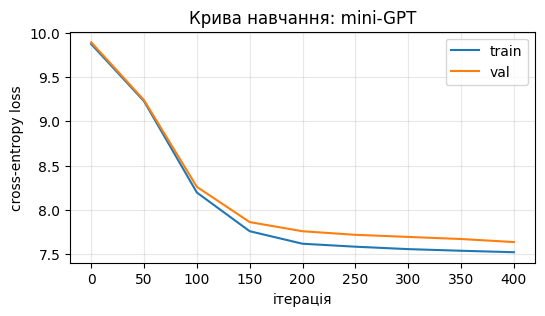

In [20]:
plt.figure(figsize=(6, 3))
plt.plot(checkpoint_iters, train_losses, label="train")
plt.plot(checkpoint_iters, val_losses, label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


### 3.10. Генерація на різних стадіях тренування

Порівнюємо якість тексту на першому збереженому чекпоінті (майже випадкова
ініціалізація) і на найкращому за val_loss (не обов'язково останньому —
модель могла почати переучуватись ближче до кінця тренування) — той самий
промпт в обох випадках.

In [21]:
PROMPT = 'Реве та стогне'
print('Перший checkpoint:')
print(generate_checkpoint(FIRST_CKPT_PATH, PROMPT))
print('Найкращий checkpoint:')
print(generate_checkpoint(BEST_CKPT_PATH, PROMPT))


Перший checkpoint:
Реве та стогне Людина вийстрілля святих приве уяви бов Муд канап пень чужомулуш риднятиалу госп сильний довікуїхала староїускає рідних чув лед працюватинала золотом Маллед бачишКрас колод �раст зеленій звернувсяахусянатолроп шовк шкіри погодилої охорон іншаДок любовінив темнийлюють вхоп пт вікноКрасщеними тіланин самотній
Найкращий checkpoint:
Реве та стогне,
у
 не?, на у,
В, не

,.

 не!,


.
.,

,,

 в,.


 як,


. і,


, " не не
 і



### 3.11. EVAL_INTERVAL: 50 і 10

demo_minigpt_eval10: iter=0, train=9.8720, val=9.8922
demo_minigpt_eval10: iter=100, train=8.1964, val=8.2604
demo_minigpt_eval10: iter=200, train=7.6184, val=7.7594
demo_minigpt_eval10: iter=300, train=7.5577, val=7.6955
demo_minigpt_eval10: iter=400, train=7.5228, val=7.6375


,model,eval_interval,eval_points,training_seconds,evaluation_seconds,val_loss,best_iteration
0,demo_minigpt,50,9,5.898157,0.519990,7.637468,400
1,demo_minigpt_eval10,10,41,8.282626,1.160063,7.637468,400


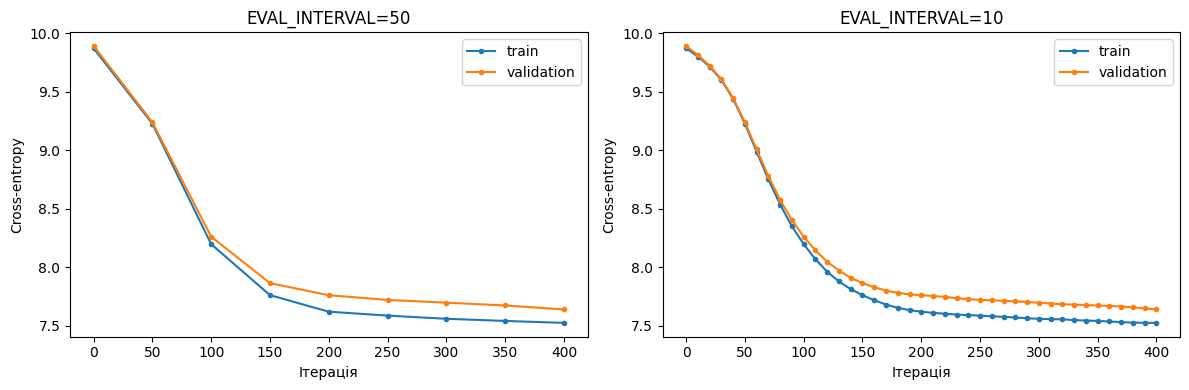

In [22]:
dense_config = dict(demo_config)
dense_config['eval_interval'] = EVAL_INTERVAL // 5
dense_record, dense_history = train_minigpt('demo_minigpt_eval10', dense_config,
    demo_splits, bpe_tokenizer, ARTIFACT_DIR, device)
frequency_table = pd.DataFrame([demo_record, dense_record])[
    ['model', 'eval_interval', 'eval_points', 'training_seconds', 'evaluation_seconds',
     'val_loss', 'best_iteration']]
display(frequency_table)
frequency_table.to_csv(ARTIFACT_DIR / 'data/eval_interval_comparison.csv', index=False)
pd.DataFrame([demo_record, dense_record]).assign(section='demo_minigpt').to_csv(
    ARTIFACT_DIR / 'data/demo_results.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, frame, label in [(axes[0], demo_history, 'EVAL_INTERVAL=50'),
                          (axes[1], dense_history, 'EVAL_INTERVAL=10')]:
    ax.plot(frame['iteration'], frame['train_loss'], marker='.', label='train')
    ax.plot(frame['iteration'], frame['val_loss'], marker='.', label='validation')
    ax.set_title(label)
    ax.set_xlabel('Ітерація')
    ax.set_ylabel('Cross-entropy')
    ax.legend()
plt.tight_layout()
plt.show()


---
## 4. Sampling playground: готова модель

Власна mini-GPT замала, щоб переконливо демонструвати ефект temperature/
top-p — для цього візьмемо малу, але вже по-справжньому навчену відкриту
модель.

### 4.1. Завантажуємо готову модель

In [23]:
del model, data, train_data, val_data, demo_splits, poems_df, poems_dataset
del corpus_text, words, unique_words, poems_list
clear_memory()
from transformers import AutoModelForCausalLM, AutoTokenizer
MODEL_ID = 'Qwen/Qwen3-0.6B'
hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
hf_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32 if device.type == 'cpu' else torch.float16).to(device)
hf_model.eval()
print('Модель:', MODEL_ID)
print('Кількість параметрів:', sum(parameter.numel() for parameter in hf_model.parameters()))


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Модель: Qwen/Qwen3-0.6B
Кількість параметрів: 596049920


### 4.2. Той самий промпт, різна температура/top-p

Той самий українськомовний промпт генеруємо з різними temperature і top-p.
Порівнюємо тексти за однакового ліміту нових токенів.

In [24]:
def hf_generate(prompt, temperature, top_p, max_new_tokens=64, enable_thinking=False):
    set_seed(SEED + 3)
    text = hf_tokenizer.apply_chat_template([{'role': 'user', 'content': prompt}],
        tokenize=False, add_generation_prompt=True, enable_thinking=enable_thinking)
    inputs = hf_tokenizer(text, return_tensors='pt').to(device)
    before = time.perf_counter()
    with torch.no_grad():
        outputs = hf_model.generate(**inputs, max_new_tokens=max_new_tokens,
            do_sample=True, temperature=temperature, top_p=top_p, top_k=0)
    generated = outputs[0][inputs.input_ids.shape[-1]:]
    raw = hf_tokenizer.decode(generated, skip_special_tokens=True)
    if enable_thinking:
        reasoning, separator, answer = raw.partition('</think>')
        answer = answer.strip() if separator else ''
        thinking_tokens = len(hf_tokenizer.encode(reasoning, add_special_tokens=False))
    else:
        answer, thinking_tokens = raw.strip(), 0
    return {'answer': answer, 'temperature': temperature, 'top_p': top_p,
        'enable_thinking': enable_thinking, 'tokens': len(generated),
        'thinking_tokens': thinking_tokens, 'seconds': time.perf_counter() - before}

PLAYGROUND_PROMPT = ('Продовж речення українською: Якось уночі студент '
    'Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка')
sampling_results = []
for temperature, top_p in [(0.2, 0.1), (0.8, 0.6), (1.4, 0.8)]:
    result = hf_generate(PLAYGROUND_PROMPT, temperature, top_p)
    sampling_results.append(result)
    show_json(result)
(ARTIFACT_DIR / 'data/demo_sampling.json').write_text(
    json.dumps(sampling_results, ensure_ascii=False, indent=2), encoding='utf-8')


{
  "answer": "Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка.",
  "temperature": 0.2,
  "top_p": 0.1,
  "enable_thinking": false,
  "tokens": 52,
  "thinking_tokens": 0,
  "seconds": 7.762825084000042
}
{
  "answer": "підвівся з ліжка, він звів у звіті про відкриття місця, якого змінили з кількох років тому.",
  "temperature": 0.8,
  "top_p": 0.6,
  "enable_thinking": false,
  "tokens": 59,
  "thinking_tokens": 0,
  "seconds": 2.4960572200000115
}
{
  "answer": "оже підвілся з ліжка театральні ворохі з вніских виразів, мишнодток happen.",
  "temperature": 1.4,
  "top_p": 0.8,
  "enable_thinking": false,
  "tokens": 40,
  "thinking_tokens": 0,
  "seconds": 1.6938104900000326
}


793

### 4.3. enable_thinking: False і True

In [25]:
thinking_results = []
for enabled in [False, True]:
    result = hf_generate(PLAYGROUND_PROMPT, temperature=0.8, top_p=0.9,
                         max_new_tokens=128, enable_thinking=enabled)
    thinking_results.append(result)
    show_json(result)
(ARTIFACT_DIR / 'data/demo_thinking.json').write_text(
    json.dumps(thinking_results, ensure_ascii=False, indent=2), encoding='utf-8')
del hf_model, hf_tokenizer
clear_memory()


{
  "answer": "підвівся з ліжка, він тих, як з той квіт, зійшов у міжнародну зону, але зійшов зустрічьо як на морі.",
  "temperature": 0.8,
  "top_p": 0.9,
  "enable_thinking": false,
  "tokens": 66,
  "thinking_tokens": 0,
  "seconds": 3.44957604800004
}
{
  "answer": "",
  "temperature": 0.8,
  "top_p": 0.9,
  "enable_thinking": true,
  "tokens": 128,
  "thinking_tokens": 128,
  "seconds": 5.9571788460000334
}
